## Plot namespace requests at Open VSX

This a plot of [namespace-stats.csv](https://raw.githubusercontent.com/EclipseFdn/open-vsx.org/refs/heads/namespace-stats/namespace-stats/namespace-stats.csv). This file is generated by [handle new issue](https://github.com/EclipseFdn/open-vsx.org/blob/aws-main/.github/workflows/new-namespace-issue-stats.yml) action that runs when a new issue is created. The action extracts the requested namespace from the issue title or body (if it exists) and then determines if the namespace is also a publisher account on the VS Code Marketplace and if so, if the account has extensions.

What we're trying to determine is the frequency of publishers coming first to Open VSX vs the VS Code Marketplace. While note entirely precise, we're using the following definitions:
- Publisher starts at Open VSX: total number of rows to date with 'VS Code Marketplace' = False or 'VS Code Marketplace' = True and 'VS Code Extensions' =  False
- Publisher starts at VS Code Marketplace: total number of rows to date with 'VS Code Marketplace' = True and 'VS Code Extensions' =  True

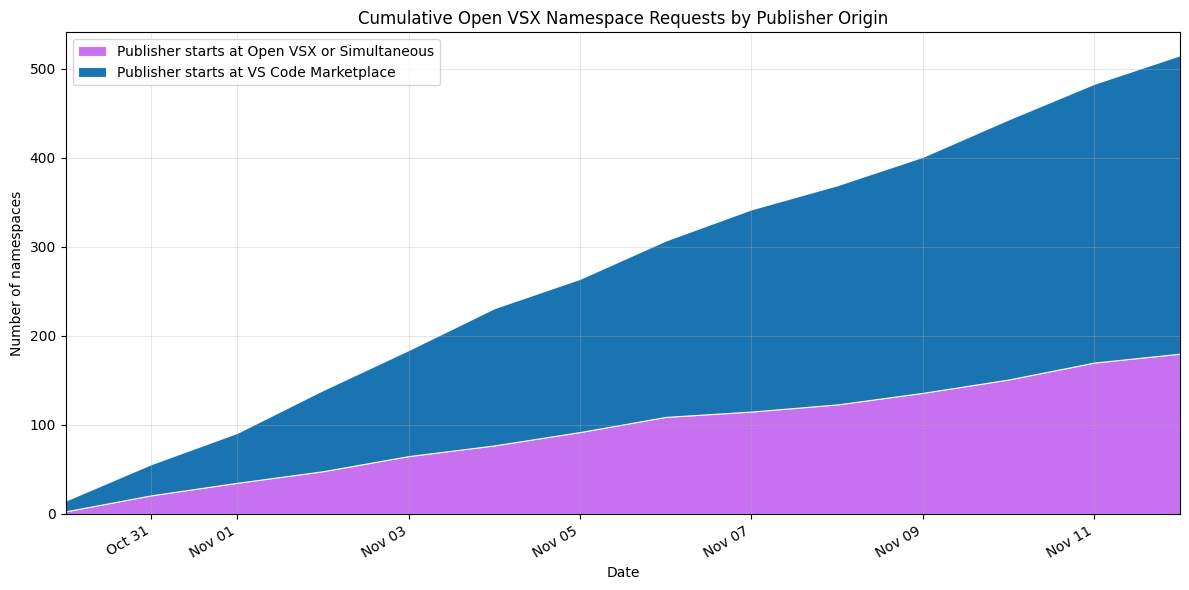

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

URL = ("https://raw.githubusercontent.com/EclipseFdn/open-vsx.org/"
       "refs/heads/namespace-stats/namespace-stats/namespace-stats.csv")

# Load; the header has spaces after the commas, so strip them
df = pd.read_csv(URL, skipinitialspace=True)
df.columns = df.columns.str.strip()

# Clean: remove rows with no Namespace
df = df[df["Namespace"].notna() & (df["Namespace"].astype(str).str.strip() != "")].copy()

# Remove duplicate requests, keeping each namespace's first request
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
df["ns_key"] = df["Namespace"].astype(str).str.strip().str.lower()
df = (df.sort_values(["Date", "GitHub Issue"])
        .drop_duplicates(subset="ns_key", keep="first")
        .drop(columns="ns_key"))

df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")

def to_bool(series):
    return series.astype(str).str.strip().str.lower() == "true"

marketplace = to_bool(df["VS Code Marketplace?"])
extensions = to_bool(df["VS Code Extensions?"])

OPEN_VSX = "Publisher starts at Open VSX or Simultaneous"
MARKETPLACE = "Publisher starts at VS Code Marketplace"

# Marketplace=True and Extensions=True -> VS Code Marketplace; everything else -> Open VSX
df["Category"] = OPEN_VSX
df.loc[marketplace & extensions, "Category"] = MARKETPLACE

# Count rows per day per category, fill in missing days, then take running totals
daily = df.groupby(["Date", "Category"]).size().unstack(fill_value=0)
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(index=all_days, columns=[OPEN_VSX, MARKETPLACE], fill_value=0)
cumulative = daily.cumsum()

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
OPEN_VSX_PURPLE = "#C160EF"   # Open VSX logo (light purple)
VSCODE_BLUE = "#0065A9"       # VS Code icon (dark blue)

ax.stackplot(
    cumulative.index,
    cumulative[OPEN_VSX],
    cumulative[MARKETPLACE],
    labels=[OPEN_VSX, MARKETPLACE],
    colors=[OPEN_VSX_PURPLE, VSCODE_BLUE],
    alpha=0.9,
    edgecolor="white",
    linewidth=0.8,
)

ax.set_title("Cumulative Open VSX Namespace Requests by Publisher Origin")
ax.set_xlabel("Date")
ax.set_ylabel("Number of namespaces")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
ax.margins(x=0)

ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

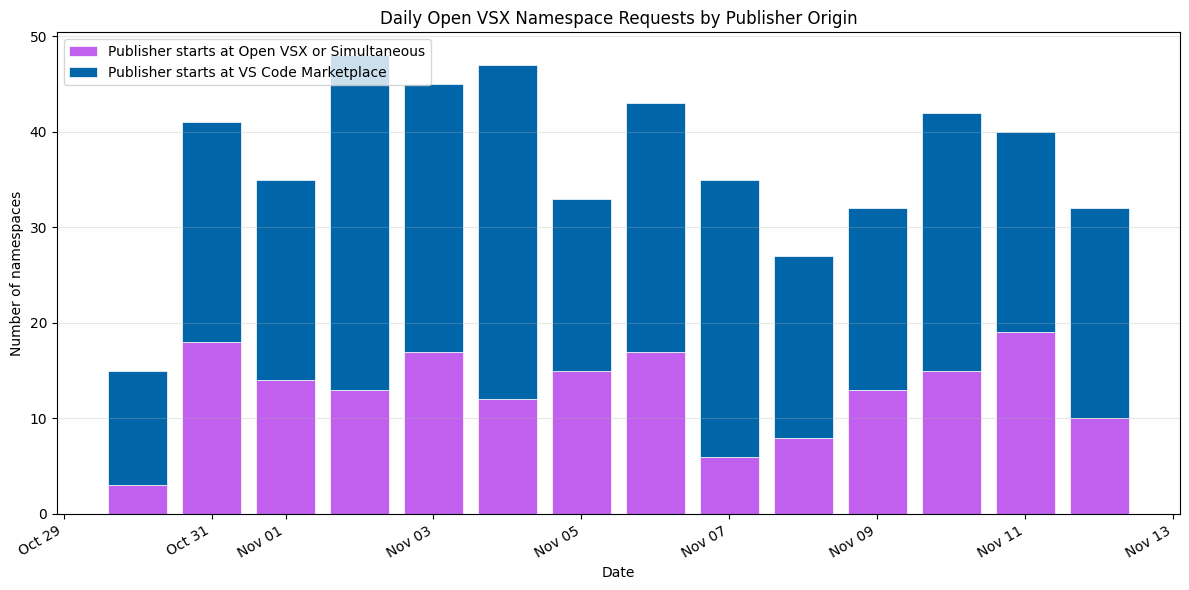

In [2]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(daily.index, daily[OPEN_VSX], width=0.8,
       label=OPEN_VSX, color=OPEN_VSX_PURPLE, edgecolor="white", linewidth=0.5)
ax.bar(daily.index, daily[MARKETPLACE], width=0.8, bottom=daily[OPEN_VSX],
       label=MARKETPLACE, color=VSCODE_BLUE, edgecolor="white", linewidth=0.5)

ax.set_title("Daily Open VSX Namespace Requests by Publisher Origin")
ax.set_xlabel("Date")
ax.set_ylabel("Number of namespaces")
ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.3)

ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

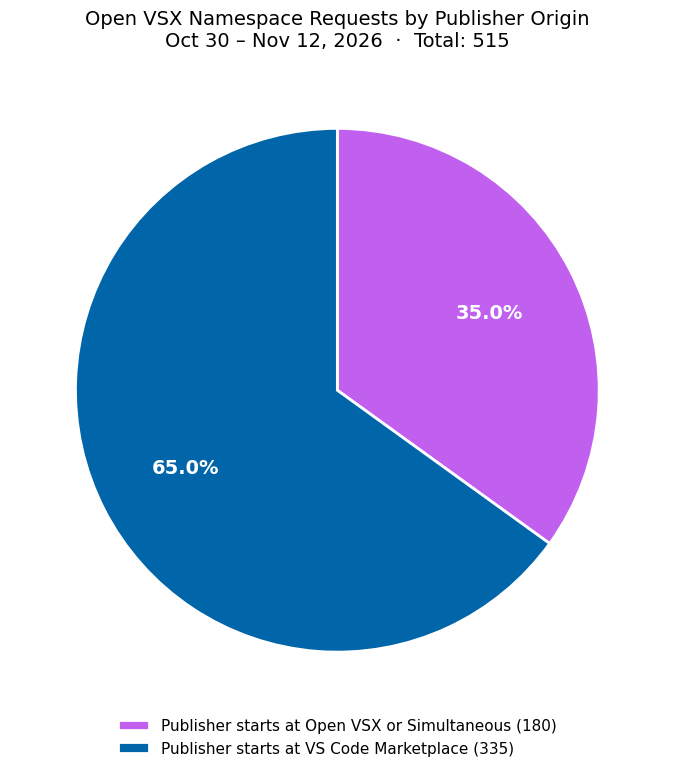

In [3]:
totals = daily[[OPEN_VSX, MARKETPLACE]].sum()

fig, ax = plt.subplots(figsize=(7, 7.5))
wedges, _, autotexts = ax.pie(
    totals,
    colors=[OPEN_VSX_PURPLE, VSCODE_BLUE],
    autopct="%1.1f%%",
    pctdistance=0.65,
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)

for t in autotexts:
    t.set_color("white")
    t.set_fontsize(14)
    t.set_fontweight("bold")

start, end = daily.index.min(), daily.index.max()
if start.year == end.year:
    date_range = f"{start:%b %-d} – {end:%b %-d, %Y}"
else:
    date_range = f"{start:%b %-d, %Y} – {end:%b %-d, %Y}"

ax.set_title(
    f"Open VSX Namespace Requests by Publisher Origin\n"
    f"{date_range}  ·  Total: {totals.sum():,}",
    fontsize=14, pad=12,
)

ax.legend(
    wedges,
    [f"{name} ({count:,})" for name, count in totals.items()],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=1,
    frameon=False,
    fontsize=11,
)

plt.tight_layout()
plt.show()